# Step 7 · SFT Data Preparation
Turn the raw split records (`{id, query, tools, answers}`) into **chat conversations in Qwen's native template**, ready for SFT.

```
raw record → messages (system + user + assistant) → rendered with Qwen's chat template → checked → saved
```

**The rule this notebook is built around:** the model is trained with **exactly the same prompt template** it's evaluated with. Only the *data* differs between training and testing (different questions); the *template* is the same. So the prompt is **imported from `src/prompts.py`**, the same module the baseline evaluation used, instead of being defined here. If the two ever differed, a base → SFT score change would mix up "what the model learned" with "how it reacts to an unfamiliar prompt".

## Setup

In [1]:
import json
import hashlib
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

# find the repo root (the folder containing src/), wherever this notebook lives
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

# find the data folder (the nearest one that has splits/)
DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "splits").is_dir())

from src.data_utils import read_jsonl                                            # noqa: E402
from src.prompts import PROMPT_VERSION, SYSTEM_PROMPT, build_messages, format_answer  # noqa: E402

print("Repo root:", REPO_ROOT)
print("Data dir: ", DATA_DIR)
print("Prompt version:", PROMPT_VERSION)

Repo root: c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning
Data dir:  c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\data
Prompt version: v1


## Config
- `LENGTH_COVERAGE`: `MAX_SEQ_LEN` is set so 99.5% of training examples fit, rounded up to a multiple of 256.
- Longer examples are **dropped, not truncated**: a cut-off example loses its answer, and training on it teaches the model nothing (or something wrong).

In [2]:
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

SPLITS_DIR = DATA_DIR / "splits"
SFT_DIR = DATA_DIR / "sft"
SFT_DIR.mkdir(parents=True, exist_ok=True)

LENGTH_COVERAGE = 0.995
ROUND_TO = 256

# Qwen's marker for "the assistant's answer starts here"; used for answer-only training
RESPONSE_MARKER = "<|im_start|>assistant\n"

## Load the splits

In [3]:
sft_train = read_jsonl(SPLITS_DIR / "sft_train.jsonl")
sft_val = read_jsonl(SPLITS_DIR / "sft_val.jsonl")

print(f"SFT train: {len(sft_train):,}")
print(f"SFT val:   {len(sft_val):,}")

# leakage guard: no training/val question may also be in test or the DPO pool
held_out_ids = {r["id"] for r in read_jsonl(SPLITS_DIR / "test.jsonl")} | {r["id"] for r in read_jsonl(SPLITS_DIR / "dpo_pool.jsonl")}
train_ids, val_ids = {r["id"] for r in sft_train}, {r["id"] for r in sft_val}

assert len(train_ids) == len(sft_train) and len(val_ids) == len(sft_val), "duplicate ids"
assert not (train_ids & val_ids), "train/val overlap"
assert not ((train_ids | val_ids) & held_out_ids), "train/val overlaps test or dpo_pool"
print("No id overlap with val / test / dpo_pool ✅")

SFT train: 48,658
SFT val:   1,170
No id overlap with val / test / dpo_pool ✅


In [4]:
example = sft_train[0]

print("QUERY:")
print(example["query"])

print("\nTOOLS:")
print(json.dumps(example["tools"], indent=2))

print("\nANSWER:")
print(json.dumps(example["answers"], indent=2))

QUERY:
Where can I find live giveaways for beta access and games?

TOOLS:
[
  {
    "name": "live_giveaways_by_type",
    "description": "Retrieve live giveaways from the GamerPower API based on the specified type.",
    "parameters": {
      "type": {
        "description": "The type of giveaways to retrieve (e.g., game, loot, beta).",
        "type": "str",
        "default": "game"
      }
    }
  }
]

ANSWER:
[
  {
    "name": "live_giveaways_by_type",
    "arguments": {
      "type": "beta"
    }
  },
  {
    "name": "live_giveaways_by_type",
    "arguments": {
      "type": "game"
    }
  }
]


## Tokenizer
`trust_remote_code` is left **off**. Qwen2.5 is supported natively by `transformers`, and that flag lets a model repo run arbitrary Python on your machine. Only turn it on for models that explicitly require it.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

assert tokenizer.chat_template is not None, "this tokenizer has no chat template"
print("Chat template available: True")
print("EOS token:", tokenizer.eos_token, "| PAD token:", tokenizer.pad_token)

Chat template available: True
EOS token: <|im_end|> | PAD token: <|endoftext|>


## What Qwen expects: its chat template
A chat model never sees "messages". It sees **one long string** in a fixed layout it learned during its own training. The tokenizer holds a small program (a **Jinja template**, `tokenizer.chat_template`) that turns a list of messages into that layout.

Qwen uses the **ChatML** layout:
```
<|im_start|>system
...system prompt...<|im_end|>
<|im_start|>user
...user message...<|im_end|>
<|im_start|>assistant
...answer...<|im_end|>
```
- `<|im_start|>` / `<|im_end|>` are **special tokens**: single token ids the model treats as structure, not text.
- The word after `<|im_start|>` is the **role**.
- `<|im_end|>` after the assistant's answer is the **stop signal**. Generation ends when the model produces it.

Below: the special tokens, the template itself, and what it produces.

In [6]:
# the special tokens that define the structure: each is ONE token id
for tok in ["<|im_start|>", "<|im_end|>", "<|endoftext|>"]:
    tid = tokenizer.convert_tokens_to_ids(tok)
    print(f"{tok:15} -> id {tid}")

print("\nEOS (generation stops here):", tokenizer.eos_token)
print("\n----- the chat template (Jinja) — first 40 lines -----")
print("\n".join(tokenizer.chat_template.splitlines()[:40]))

<|im_start|>    -> id 151644
<|im_end|>      -> id 151645
<|endoftext|>   -> id 151643

EOS (generation stops here): <|im_end|>

----- the chat template (Jinja) — first 40 lines -----
{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['r

In [7]:
# a tiny conversation, to see the layout without 2,000 characters of tool schemas
toy = [
    {"role": "system", "content": "You are a helpful assistant."},
    {"role": "user", "content": "What is 2 + 2?"},
    {"role": "assistant", "content": "4"},
]

print("----- training layout (full conversation) -----")
print(tokenizer.apply_chat_template(toy, tokenize=False))

print("----- inference layout (no answer yet, add_generation_prompt=True) -----")
print(tokenizer.apply_chat_template(toy[:-1], tokenize=False, add_generation_prompt=True))

----- training layout (full conversation) -----
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
What is 2 + 2?<|im_end|>
<|im_start|>assistant
4<|im_end|>

----- inference layout (no answer yet, add_generation_prompt=True) -----
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
What is 2 + 2?<|im_end|>
<|im_start|>assistant



In [8]:
# what happens if you forget the system message: Qwen inserts its own default
no_system = tokenizer.apply_chat_template(toy[1:], tokenize=False)
print(no_system)
print("Lesson: always pass our system prompt, otherwise Qwen silently adds its default one.")

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
What is 2 + 2?<|im_end|>
<|im_start|>assistant
4<|im_end|>

Lesson: always pass our system prompt, otherwise Qwen silently adds its default one.


### For comparison: Qwen's *native* tool-calling format (we don't use it)
Qwen2.5 also has a built-in tool format: pass `tools=` to the template, and it lists the tools inside `<tools>` tags in the system prompt and writes calls as `<tool_call>{...}</tool_call>`.

We deliberately **don't** use it. The baseline was measured with our own prompt (`src/prompts.py`), and training must use the same template. It's shown here so you can see both side by side, and as an option for a future experiment (it would need its own baseline).

The native format needs tools as **JSON Schema** (`"type": "string"`, `"required": [...]`), so the xLAM tool is converted first.

In [9]:
from src.data_utils import is_required

XLAM_TO_JSON_TYPE = {"str": "string", "int": "integer", "float": "number", "bool": "boolean",
                     "list": "array", "tuple": "array", "set": "array", "dict": "object"}


def xlam_to_native_tool(tool):
    """xLAM tool -> OpenAI/Qwen-style JSON Schema tool (for display only)."""
    props, required = {}, []
    for name, info in (tool.get("parameters") or {}).items():
        base = str(info.get("type", "")).split(",")[0].strip().lower()
        base = next((v for k, v in XLAM_TO_JSON_TYPE.items() if base.startswith(k)), "string")
        props[name] = {"type": base, "description": info.get("description", "")}
        if is_required(info):
            required.append(name)
    return {"type": "function", "function": {
        "name": tool["name"], "description": tool.get("description", ""),
        "parameters": {"type": "object", "properties": props, "required": required}}}


native_tools = [xlam_to_native_tool(t) for t in example["tools"]]
native_messages = [
    {"role": "user", "content": example["query"]},
    {"role": "assistant", "content": "", "tool_calls": [
        {"type": "function", "function": {"name": c["name"], "arguments": c["arguments"]}}
        for c in example["answers"]
    ]},
]

try:
    native_text = tokenizer.apply_chat_template(native_messages, tools=native_tools, tokenize=False)
    print(native_text)
except Exception as e:
    print(f"This tokenizer's template couldn't render native tool calls: {e!r}")

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "live_giveaways_by_type", "description": "Retrieve live giveaways from the GamerPower API based on the specified type.", "parameters": {"type": "object", "properties": {"type": {"type": "string", "description": "The type of giveaways to retrieve (e.g., game, loot, beta)."}}, "required": []}}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
Where can I find live giveaways for beta access and games?<|im_end|>
<|im_start|>assistant
<tool_call>
{"name": "live_giveaways_by_type", "arguments": {"type": "beta"}}
</tool_

## Build the training conversation
`build_messages(record)` from `src/prompts.py` gives **system + user**, exactly what the model sees at evaluation time. For training we just append the correct answer as the **assistant** turn.

That construction *guarantees* the training text starts with the evaluation prompt (check #3 below verifies it anyway).

In [10]:
def build_training_messages(record):
    return build_messages(record) + [
        {"role": "assistant", "content": format_answer(record["answers"])}
    ]


messages = build_training_messages(example)

for message in messages:
    print(f"\n--- {message['role'].upper()} ---")
    print(message["content"][:2000])


--- SYSTEM ---
You are a function-calling assistant.

Your task is to select the appropriate tool and provide the arguments required
to answer the user's request.

Return ONLY valid JSON.

The output must be a JSON array of tool calls in this format:

[
  {
    "name": "function_name",
    "arguments": {
      "argument_name": "value"
    }
  }
]

If none of the available tools can answer the request, return an empty array: []

Do not explain your answer.
Do not output markdown.
Do not invent tools.


--- USER ---
Available tools:

[
  {
    "name": "live_giveaways_by_type",
    "description": "Retrieve live giveaways from the GamerPower API based on the specified type.",
    "parameters": {
      "type": {
        "description": "The type of giveaways to retrieve (e.g., game, loot, beta).",
        "type": "str",
        "default": "game"
      }
    }
  }
]

User request:

Where can I find live giveaways for beta access and games?

Return the required tool call(s) as JSON.

--- ASSI

## Render with Qwen's chat template
What you should see:
- every turn wrapped in `<|im_start|>role` … `<|im_end|>`
- the **training text** ending with the JSON answer followed by `<|im_end|>`, which is how the model learns to *stop* (the models that rambled in model selection never learned this)
- the **inference prompt** ending with `<|im_start|>assistant\n`, where generation begins

In [11]:
formatted_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
inference_prompt = tokenizer.apply_chat_template(messages[:-1], tokenize=False, add_generation_prompt=True)

print("=" * 30, "TRAINING TEXT", "=" * 30)
print(formatted_text)
print("=" * 30, "INFERENCE PROMPT (last 200 chars)", "=" * 30)
print(repr(inference_prompt[-200:]))

============================== TRAINING TEXT ==============================
<|im_start|>system
You are a function-calling assistant.

Your task is to select the appropriate tool and provide the arguments required
to answer the user's request.

Return ONLY valid JSON.

The output must be a JSON array of tool calls in this format:

[
  {
    "name": "function_name",
    "arguments": {
      "argument_name": "value"
    }
  }
]

If none of the available tools can answer the request, return an empty array: []

Do not explain your answer.
Do not output markdown.
Do not invent tools.
<|im_end|>
<|im_start|>user
Available tools:

[
  {
    "name": "live_giveaways_by_type",
    "description": "Retrieve live giveaways from the GamerPower API based on the specified type.",
    "parameters": {
      "type": {
        "description": "The type of giveaways to retrieve (e.g., game, loot, beta).",
        "type": "str",
        "default": "game"
      }
    }
  }
]

User request:

Where can I find li

In [12]:
# round trip: encode -> decode must give back the same text (no odd characters lost)
ids = tokenizer(formatted_text, add_special_tokens=False)["input_ids"]
assert tokenizer.decode(ids, skip_special_tokens=False) == formatted_text
print("Token count:", len(ids), "| encode/decode round trip ✅")

Token count: 283 | encode/decode round trip ✅


## Side by side: what Qwen expects vs our training text
Our example, cut into its turns. Each turn should look exactly like the toy example above: starting with `<|im_start|>role`, ending with `<|im_end|>`, in the order system → user → assistant. Then a checklist of every structural rule.

In [13]:
# split the rendered text into turns
turns = []
for chunk in formatted_text.split("<|im_start|>")[1:]:
    role, _, body = chunk.partition("\n")
    content = body.split("<|im_end|>")[0]
    turns.append({
        "role": role,
        "ends_with_<|im_end|>": "<|im_end|>" in body,
        "tokens": len(tokenizer(content, add_special_tokens=False)["input_ids"]),
        "starts_with": content[:60].replace("\n", "⏎ "),
        "ends_with": content[-60:].replace("\n", "⏎ "),
    })

with pd.option_context("display.max_colwidth", 70):
    display(pd.DataFrame(turns))

,role,ends_with_<|im_end|>,tokens,starts_with,ends_with
0,system,True,110,You are a function-calling assistant.⏎ ⏎ Your task is to selec,n your answer.⏎ Do not output markdown.⏎ Do not invent tools.⏎
1,user,True,115,"Available tools:⏎ ⏎ [⏎ {⏎ ""name"": ""live_giveaways_by_type""",access and games?⏎ ⏎ Return the required tool call(s) as JSON.
2,assistant,True,43,"[{""name"": ""live_giveaways_by_type"", ""arguments"": {""type"": ""b",""": ""live_giveaways_by_type"", ""arguments"": {""type"": ""game""}}]"


In [14]:
# every structural rule Qwen's format needs, checked on our text
expected_toy = tokenizer.apply_chat_template(toy, tokenize=False)

structure_checks = {
    "starts with <|im_start|>system":               formatted_text.startswith("<|im_start|>system\n"),
    "our system prompt (not Qwen's default)":       SYSTEM_PROMPT in formatted_text and "You are Qwen" not in formatted_text,
    "system -> user boundary":                       "<|im_end|>\n<|im_start|>user\n" in formatted_text,
    "user -> assistant boundary":                    "<|im_end|>\n<|im_start|>assistant\n" in formatted_text,
    "exactly 3 turns":                               formatted_text.count("<|im_start|>") == 3,
    "every turn closed":                             formatted_text.count("<|im_start|>") == formatted_text.count("<|im_end|>"),
    "answer is last, followed by <|im_end|>":        formatted_text.rstrip().endswith(messages[-1]["content"] + "<|im_end|>"),
    "same layout as Qwen's toy example":             expected_toy.split("You are a helpful")[0] == formatted_text.split("You are a function")[0],
    "starts with the inference prompt":              formatted_text.startswith(inference_prompt),
}

display(pd.DataFrame({"check": structure_checks.keys(),
                      "ok": ["✅" if v else "❌" for v in structure_checks.values()]}))
assert all(structure_checks.values()), "our text does not match Qwen's expected structure"

,check,ok
0,starts with <|im_start|>system,✅
1,our system prompt (not Qwen's default),✅
2,system -> user boundary,✅
3,user -> assistant boundary,✅
4,exactly 3 turns,✅
5,every turn closed,✅
6,"answer is last, followed by <|im_end|>",✅
7,same layout as Qwen's toy example,✅
8,starts with the inference prompt,✅


## Convert every example
Each saved row keeps:
- `id`: traces back to the raw data
- `messages`: the conversation (system, user, assistant). Use it for conversational trainers, or take `messages[:-1]` / `messages[-1:]` as prompt / completion.
- `text`: the rendered template, used by text-based trainers (e.g. Unsloth + `train_on_responses_only`)

In [15]:
def to_sft_row(record):
    msgs = build_training_messages(record)
    return {
        "id": record["id"],
        "messages": msgs,
        "text": tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=False),
    }


def token_lengths(texts, batch_size=2000):
    """Count tokens in batches and keep only the counts (holding 50k id lists at once wastes RAM)."""
    lengths = []
    for i in range(0, len(texts), batch_size):
        ids = tokenizer(texts[i:i + batch_size], add_special_tokens=False)["input_ids"]
        lengths.extend(len(x) for x in ids)
    return lengths


train_rows = [to_sft_row(r) for r in sft_train]
val_rows = [to_sft_row(r) for r in sft_val]

for rows in (train_rows, val_rows):
    for row, n in zip(rows, token_lengths([r["text"] for r in rows])):
        row["_n_tokens"] = n

print(f"Converted {len(train_rows):,} train and {len(val_rows):,} val examples")

Converted 48,658 train and 1,170 val examples


## Sequence length → `MAX_SEQ_LEN`
The length filter in the cleaning notebook measured a *simpler* format. This template is longer (detailed system prompt + indented tools), so lengths are **recomputed here with the real template**. That's the number the trainer will actually see.

count    48658.0
mean       582.0
std        245.0
min        226.0
50%        539.0
90%        923.0
95%       1075.0
99%       1328.0
99.5%     1404.0
max       1615.0
dtype: float64

MAX_SEQ_LEN = 1536


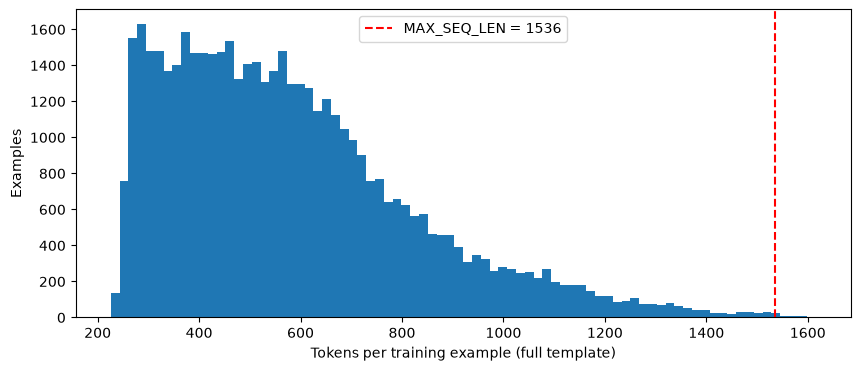

In [16]:
train_lengths = np.array([r["_n_tokens"] for r in train_rows])

MAX_SEQ_LEN = int(np.ceil(np.quantile(train_lengths, LENGTH_COVERAGE) / ROUND_TO) * ROUND_TO)

print(pd.Series(train_lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99, 0.995]).round(0))
print(f"\nMAX_SEQ_LEN = {MAX_SEQ_LEN}")

plt.figure(figsize=(10, 4))
plt.hist(train_lengths, bins=80)
plt.axvline(MAX_SEQ_LEN, color="red", linestyle="--", label=f"MAX_SEQ_LEN = {MAX_SEQ_LEN}")
plt.xlabel("Tokens per training example (full template)")
plt.ylabel("Examples")
plt.legend()
plt.show()

In [17]:
too_long_train = [r for r in train_rows if r["_n_tokens"] > MAX_SEQ_LEN]
too_long_val = [r for r in val_rows if r["_n_tokens"] > MAX_SEQ_LEN]

train_rows = [r for r in train_rows if r["_n_tokens"] <= MAX_SEQ_LEN]
val_rows = [r for r in val_rows if r["_n_tokens"] <= MAX_SEQ_LEN]

print(f"Dropped (too long): train {len(too_long_train):,}, val {len(too_long_val):,}")
print(f"Remaining:          train {len(train_rows):,}, val {len(val_rows):,}")

Dropped (too long): train 42, val 1
Remaining:          train 48,616, val 1,169


## Format checks (on **every** example, not just one)
| # | Check | Why |
|---|---|---|
| 1 | Roles are exactly system → user → assistant, contents are non-empty strings | malformed conversations break the template |
| 2 | Assistant content parses as JSON and equals the gold answer | the label must be exactly the right answer |
| 3 | Training text **starts with** the inference prompt | train and eval format are identical; the #1 silent SFT bug |
| 4 | Training text ends with `answer + <\|im_end\|>` | the model learns to stop after the JSON |
| 5 | System + user turns are identical to `src/prompts.py` | nothing drifted from the baseline template |
| 6 | Every example ≤ `MAX_SEQ_LEN` tokens | nothing gets silently cut off |

In [18]:
def check_row(row, record):
    msgs = row["messages"]

    # 1. structure
    assert [m["role"] for m in msgs] == ["system", "user", "assistant"], "roles"
    assert all(isinstance(m["content"], str) and m["content"].strip() for m in msgs), "empty content"

    # 2. label is the gold answer
    assert json.loads(msgs[-1]["content"]) == record["answers"], "assistant != gold answer"

    # 3. training text starts with the exact inference prompt
    prompt = tokenizer.apply_chat_template(msgs[:-1], tokenize=False, add_generation_prompt=True)
    assert row["text"].startswith(prompt), "training text does not start with inference prompt"

    # 4. ends with the answer + end-of-turn token
    assert row["text"].rstrip().endswith(msgs[-1]["content"] + "<|im_end|>"), "missing <|im_end|> after answer"

    # 5. same template as the baseline evaluation
    assert msgs[:-1] == build_messages(record), "template drifted from src/prompts.py"
    assert msgs[0]["content"] == SYSTEM_PROMPT

    # 6. length
    assert row["_n_tokens"] <= MAX_SEQ_LEN


records_by_id = {r["id"]: r for r in sft_train + sft_val}
for rows in (train_rows, val_rows):
    for row in rows:
        check_row(row, records_by_id[row["id"]])

print(f"All 6 format checks passed on {len(train_rows) + len(val_rows):,} examples ✅")

All 6 format checks passed on 49,785 examples ✅


## Check 7: train on the answer only (loss masking)
By default a trainer learns from **every** token in `text`: system prompt, tool schemas, question *and* answer. Here ~75% of the tokens are tool schemas the model only needs to *read*, not *write*. Training on them wastes most of the effort and can teach the model to echo schemas.

**Answer-only training:** every token up to and including `<|im_start|>assistant\n` gets label `-100` (ignored by the loss). Only the answer and its `<|im_end|>` are learned.

Below we build those labels the same way the trainer will (find the last assistant marker), and check that the trained part is **exactly the answer** for every example. In the training notebook you get this with either:
- **Unsloth (text):** `train_on_responses_only(trainer, instruction_part="<|im_start|>user\n", response_part="<|im_start|>assistant\n")`
- **TRL (conversational):** pass `prompt = messages[:-1]`, `completion = messages[-1:]`. TRL then trains on the completion only by default.

Either way, **decode one batch's labels in the training notebook too**, to confirm the trainer really does this.

In [19]:
marker_ids = tokenizer(RESPONSE_MARKER, add_special_tokens=False)["input_ids"]


def answer_only_labels(input_ids):
    """-100 for everything up to the last assistant marker, real ids after it."""
    for start in range(len(input_ids) - len(marker_ids), -1, -1):
        if input_ids[start:start + len(marker_ids)] == marker_ids:
            cut = start + len(marker_ids)
            return [-100] * cut + input_ids[cut:]
    return None


def trained_text(row):
    ids = tokenizer(row["text"], add_special_tokens=False)["input_ids"]
    labels = answer_only_labels(ids)
    assert labels is not None, f"assistant marker not found in id {row['id']}"
    return tokenizer.decode([t for t in labels if t != -100], skip_special_tokens=False), labels


for row in train_rows[:3]:
    text, labels = trained_text(row)
    print(f"id {row['id']}: {sum(l != -100 for l in labels)} of {len(labels)} tokens trained -> {text!r}")

id 0: 45 of 283 tokens trained -> '[{"name": "live_giveaways_by_type", "arguments": {"type": "beta"}}, {"name": "live_giveaways_by_type", "arguments": {"type": "game"}}]<|im_end|>\n'
id 1: 22 of 329 tokens trained -> '[{"name": "web_chain_details", "arguments": {"chain_slug": "ethereum"}}]<|im_end|>\n'
id 2: 38 of 750 tokens trained -> '[{"name": "t3ma", "arguments": {"symbol": "ETH/BTC", "interval": "1h", "time_period": 14}}]<|im_end|>\n'


In [20]:
trained_share = []

for rows in (train_rows, val_rows):
    for row in rows:
        text, labels = trained_text(row)
        answer = row["messages"][-1]["content"]
        assert text.startswith(answer) and text.rstrip().endswith("<|im_end|>"), f"bad mask for id {row['id']}"
        assert text.rstrip() == answer + "<|im_end|>", f"extra tokens trained for id {row['id']}"
        trained_share.append(sum(l != -100 for l in labels) / len(labels))

print("Check 7 passed: only the answer + <|im_end|> is trained, for every example ✅")
print(f"Share of tokens actually trained: median {np.median(trained_share):.1%}")

Check 7 passed: only the answer + <|im_end|> is trained, for every example ✅
Share of tokens actually trained: median 9.2%


## Save
`data/sft/train.jsonl` and `val.jsonl` hold `{id, messages, text}`. `sft_data_report.json` records everything needed to reproduce or audit this step: template version, tokenizer, `MAX_SEQ_LEN`, drop counts, length stats, and file hashes.

In [21]:
PUBLIC_FIELDS = ["id", "messages", "text"]


def save_jsonl(path, rows):
    with path.open("w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps({k: row[k] for k in PUBLIC_FIELDS}, ensure_ascii=False) + "\n")


def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


save_jsonl(SFT_DIR / "train.jsonl", train_rows)
save_jsonl(SFT_DIR / "val.jsonl", val_rows)

# reload from disk and make sure it's what we checked
reloaded_train = read_jsonl(SFT_DIR / "train.jsonl")
reloaded_val = read_jsonl(SFT_DIR / "val.jsonl")
assert [r["id"] for r in reloaded_train] == [r["id"] for r in train_rows]
assert [r["id"] for r in reloaded_val] == [r["id"] for r in val_rows]
assert all(a["text"] == b["text"] for a, b in zip(reloaded_train, train_rows))

report = {
    "model_name": MODEL_NAME,
    "prompt_version": PROMPT_VERSION,
    "max_seq_len": MAX_SEQ_LEN,
    "length_coverage": LENGTH_COVERAGE,
    "train_examples": len(train_rows),
    "val_examples": len(val_rows),
    "dropped_too_long": {"train": len(too_long_train), "val": len(too_long_val)},
    "train_token_percentiles": {
        str(q): int(np.quantile(train_lengths, q)) for q in [0.5, 0.9, 0.95, 0.99, 0.995, 1.0]
    },
    "median_share_of_tokens_trained": round(float(np.median(trained_share)), 3),
    "response_marker": RESPONSE_MARKER,
    "files": {name: sha256_file(SFT_DIR / name) for name in ["train.jsonl", "val.jsonl"]},
}
(SFT_DIR / "sft_data_report.json").write_text(json.dumps(report, indent=2))

print("Saved:")
for name in ["train.jsonl", "val.jsonl", "sft_data_report.json"]:
    print(f"  {SFT_DIR / name}")
pd.Series({k: v for k, v in report.items() if not isinstance(v, dict)})

Saved:
  c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\data\sft\train.jsonl
  c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\data\sft\val.jsonl
  c:\Users\Swapn\OneDrive\Documents\GitHub\SLM Finetuning\notebooks\data\sft\sft_data_report.json


model_name                        Qwen/Qwen2.5-0.5B-Instruct
prompt_version                                            v1
max_seq_len                                             1536
length_coverage                                        0.995
train_examples                                         48616
val_examples                                            1169
median_share_of_tokens_trained                         0.092
response_marker                      <|im_start|>assistant\n
dtype: object

In [22]:
for i in range(3):
    print(f"\n{'=' * 80}\nEXAMPLE {i} (id {train_rows[i]['id']})\n{'=' * 80}")
    print(train_rows[i]["text"][-600:])


EXAMPLE 0 (id 0)
ways_by_type",
    "description": "Retrieve live giveaways from the GamerPower API based on the specified type.",
    "parameters": {
      "type": {
        "description": "The type of giveaways to retrieve (e.g., game, loot, beta).",
        "type": "str",
        "default": "game"
      }
    }
  }
]

User request:

Where can I find live giveaways for beta access and games?

Return the required tool call(s) as JSON.<|im_end|>
<|im_start|>assistant
[{"name": "live_giveaways_by_type", "arguments": {"type": "beta"}}, {"name": "live_giveaways_by_type", "arguments": {"type": "game"}}]<|im_end|>


EXAMPLE 1 (id 1)

  },
  {
    "name": "web_chain_details",
    "description": "python",
    "parameters": {
      "chain_slug": {
        "description": "The slug identifier for the blockchain (e.g., 'ethereum' for Ethereum mainnet).",
        "type": "str",
        "default": "ethereum"
      }
    }
  }
]

User request:

I need to understand the details of the Ethereum block

## Next: SFT training
- Load `data/sft/train.jsonl` and `val.jsonl`, with `max_seq_length = MAX_SEQ_LEN` from the report.
- Turn on **answer-only training** (Unsloth `train_on_responses_only`, or TRL prompt/completion) and **decode one batch of labels** to confirm it.
- Evaluate checkpoints on `sft_val` with the shared scorer, and the final model on the frozen test set via `03_baseline_eval.ipynb` (only `RUN_NAME` and `MODEL_PATH` change).
- Don't touch `src/prompts.py` from here on. Changing it would invalidate the baseline comparison.